# Explainability Audit of Plant Disease Models
### Grad-CAM shortcut analysis and BG-Suppress training — code and outputs

**Student:** Amogh Narendra Mulik (PRN 2417022), Department of Artificial Intelligence & Machine Learning, Rajarambapu Institute of Technology

**Models compared:** EfficientNet-B0, ResNet-50, ViT-S/16 — each trained as a *baseline* and with the proposed *BG-Suppress* method.

> **How this notebook was produced.** Training was run locally on an NVIDIA RTX 5060 Laptop GPU with the scripts in this project folder (`train.py`, `evaluate.py`). Re-running 30-epoch training inside a notebook is not practical, so the training cells show the exact commands used and print the per-epoch logs that `train.py` saved (`runs/<run>/log.csv`). Every other output below is computed directly from the saved results files.

## 1. Setup and configuration

In [1]:
import json, ast
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

import config as C   # project settings (classes, models, image size)

pd.set_option("display.width", 140)
RUNS = ["efficientnet_b0_baseline", "efficientnet_b0_bgsuppress",
        "resnet50_baseline", "resnet50_bgsuppress",
        "vit_small_baseline", "vit_small_bgsuppress"]
print("Classes (PlantVillage tomato):", C.NUM_CLASSES)
for i, n in enumerate(C.SHORT_NAMES):
    print(f"  {i}: {n}")
print("Input size:", C.IMG_SIZE, "px | seed:", C.SEED)

Classes (PlantVillage tomato): 10
  0: Bacterial spot
  1: Early blight
  2: Late blight
  3: Leaf mold
  4: Septoria
  5: Spider mites
  6: Target spot
  7: Yellow leaf curl
  8: Mosaic virus
  9: Healthy
Input size: 224 px | seed: 42


In [2]:
models = pd.DataFrame([{"model": k, "timm weights": v["timm"], "Grad-CAM layer": v["layer"], "learning rate": v["lr"]}
                       for k, v in C.MODELS.items() if k != "mobilenetv3"])
display(models)

,model,timm weights,Grad-CAM layer,learning rate
0,resnet50,resnet50.a1_in1k,layer4,0.0002
1,efficientnet_b0,efficientnet_b0.ra_in1k,bn2,0.0002
2,vit_small,vit_small_patch16_224.augreg_in21k_ft_in1k,blocks.-1.norm1,0.0001


In [3]:
# Training hyper-parameters actually used (saved by train.py in runs/<run>/args.json)
args = pd.DataFrame([json.load(open(f"runs/{r}/args.json")) for r in RUNS], index=RUNS)
display(args[["model", "mode", "epochs", "batch", "lr", "wd", "warmup", "lam", "bg_p"]])

,model,mode,epochs,batch,lr,wd,warmup,lam,bg_p
efficientnet_b0_baseline,efficientnet_b0,baseline,30,32,0.0002,0.05,2,1.0,0.8
efficientnet_b0_bgsuppress,efficientnet_b0,bgsuppress,30,32,0.0002,0.05,2,1.0,0.8
resnet50_baseline,resnet50,baseline,30,32,0.0002,0.05,2,1.0,0.8
resnet50_bgsuppress,resnet50,bgsuppress,30,32,0.0002,0.05,2,1.0,0.8
vit_small_baseline,vit_small,baseline,30,32,0.0001,0.05,2,1.0,0.8
vit_small_bgsuppress,vit_small,bgsuppress,30,32,0.0001,0.05,2,1.0,0.8


## 2. Datasets

**Lab data:** PlantVillage tomato (10 classes) with leaf masks, split 70/15/15. **Field data:** PlantDoc tomato leaves, used only for testing.

In [4]:
pv = pd.read_csv("data/pv_split.csv")
counts = pd.crosstab(pv.label.map(dict(enumerate(C.SHORT_NAMES))), pv.split)[["train", "val", "test"]]
counts.loc["Total"] = counts.sum()
display(counts)

split,train,val,test
label,,,
Bacterial spot,1489,319,319
Early blight,699,150,150
Healthy,1114,239,238
Late blight,1336,286,287
Leaf mold,666,143,143
Mosaic virus,261,56,56
Septoria,1238,265,266
Spider mites,1173,251,251
Target spot,983,211,210


In [5]:
pdoc = pd.read_csv("data/plantdoc.csv")
fc = pdoc.label.map(dict(enumerate(C.SHORT_NAMES))).value_counts().rename("images").to_frame()
display(fc)
print("Field images:", len(pdoc), "| classes present:", pdoc.label.nunique())
print(f"Uniform chance: {100 / pdoc.label.nunique():.1f}%   Majority-class baseline: {100 * fc.images.max() / len(pdoc):.1f}%")

Field images: 744 | classes present: 8
Uniform chance: 12.5%   Majority-class baseline: 20.3%


,images
label,
Septoria,151
Late blight,111
Bacterial spot,110
Leaf mold,91
Early blight,88
Yellow leaf curl,76
Healthy,63
Mosaic virus,54


## 3. Key implementation

The cells below print the core functions from the project source files: background randomisation, the counterfactual test images, Grad-CAM, the alignment loss and the focus score.

In [6]:
def show_functions(path, names):
    src = open(path).read()
    tree = ast.parse(src)
    for node in tree.body:
        if isinstance(node, (ast.FunctionDef, ast.ClassDef)) and node.name in names:
            print(ast.get_source_segment(src, node)); print()

show_functions("data.py", ["composite", "background_only", "mixed_rand"])

def composite(x01, m, bg):
    """x01 (3,H,W) in [0,1], m (1,H,W) in [0,1], bg (3,H,W)."""
    return x01 * m + bg * (1 - m)

def background_only(xn, m):
    """Leaf replaced by the normalisation mean (= 0 after normalising)."""
    return xn * (1 - m)

def mixed_rand(xn, m, labels, generator=None):
    """Each leaf pasted onto the background of another test image from a DIFFERENT class.

    The donor's own leaf area is filled with the donor's mean background colour, so no
    foreign leaf pixels leak in. Mirrors Xiao et al. (ICLR 2021) 'Mixed-Rand'.
    """
    b = xn.shape[0]
    perm = torch.arange(b)
    for i in range(b):
        cands = (labels != labels[i]).nonzero().flatten()
        if len(cands):
            perm[i] = cands[torch.randint(len(cands), (1,), generator=generator)].item()
    donor_x, donor_m = xn[perm], m[perm]
    bg_area = (1 - donor_m).sum(dim=(2, 3), keepdim=True).clamp_min(1)
    bg_mean = (donor_x * (1 - donor_m)).sum(dim=(2, 3), keepdim=True) / bg_area
  

In [7]:
show_functions("models.py", ["grad_cam", "off_leaf_loss", "lesion_focus_score"])

def grad_cam(model: CamModel, logits, target, create_graph=False):
    """Grad-CAM for class `target` (B,) from the last forward pass.

    Channel weights are always detached (stop-gradient), so with create_graph=False the
    returned map is a detached evaluation map, and with create_graph=True the map keeps a
    graph through the feature map only (cheap: no second-order gradients).
    Returns (B,h,w) float32, non-negative.
    """
    raw = model._feat
    score = logits.gather(1, target.view(-1, 1)).sum()
    g = torch.autograd.grad(score, raw, retain_graph=True)[0]
    feat = model.features()
    if model.is_vit:
        g = g[:, model.n_prefix:, :]
        b, n, c = g.shape
        s = int(n ** 0.5)
        g = g.transpose(1, 2).reshape(b, c, s, s)
    w = g.float().mean(dim=(2, 3), keepdim=True).detach()
    f = feat.float() if create_graph else feat.float().detach()
    return F.relu((w * f).sum(dim=1))

def off_leaf_loss(cam, mask):
    """Share of CAM energy outside the lea

In [8]:
# Training loss used by train.py (excerpt)
src = open("train.py").read()
start = src.index("use_bg = a.mode")
print(src[start:start + 140])
start = src.index("with torch.autocast(device.type, dtype=dtype, enabled=use_amp):\n                out = model(x)")
print(src[start:start + 420])

use_bg = a.mode in ("bgsuppress", "bgrand")
    use_att = a.mode in ("bgsuppress", "attloss")
    lr = a.lr or MODELS[a.model]["lr"]

    ru
with torch.autocast(device.type, dtype=dtype, enabled=use_amp):
                out = model(x)
                ce = F.cross_entropy(out.float(), y, label_smoothing=0.1)
            if use_att:
                cam = grad_cam(model, out.float(), y, create_graph=True)
                att = off_leaf_loss(cam, m)
            else:
                att = torch.zeros((), device=device)
            loss = ce + a.lam * att
   


## 4. Training

Commands used (from `run_main.bat`), 30 epochs per run:

In [9]:
print(open("run_main.bat").read())

@echo off
REM Main results: 3 models x (baseline, BG-Suppress), 30 epochs each.
REM Re-run this file after any crash: finished epochs/runs are resumed via --resume.
set EPOCHS=30

python train.py --model efficientnet_b0 --mode baseline   --epochs %EPOCHS% --resume || goto :err
python train.py --model resnet50        --mode baseline   --epochs %EPOCHS% --resume || goto :err
python train.py --model vit_small       --mode baseline   --epochs %EPOCHS% --resume || goto :err

python train.py --model efficientnet_b0 --mode bgsuppress --epochs %EPOCHS% --resume || goto :err
python train.py --model resnet50        --mode bgsuppress --epochs %EPOCHS% --resume || goto :err
python train.py --model vit_small       --mode bgsuppress --epochs %EPOCHS% --resume || goto :err

python evaluate.py --all || goto :err
python make_figures.py || goto :err
echo MAIN RUNS DONE. See results\results.csv and results\*.png
goto :eof

:err
echo A step failed. Fix the error above, then run this file again.
exit /b 1


Per-epoch training logs saved by `train.py` (`runs/<run>/log.csv`). `train_att` is the alignment loss (zero for baseline runs).

In [10]:
log = pd.read_csv("runs/efficientnet_b0_baseline/log.csv")
log["epoch"] += 1
print("efficientnet_b0_baseline")
print(log[["epoch", "train_loss", "train_att", "train_acc", "val_loss", "val_acc", "val_f1", "sec"]]
      .to_string(index=False, float_format=lambda v: f"{v:.4f}"))

efficientnet_b0_baseline
 epoch  train_loss  train_att  train_acc  val_loss  val_acc  val_f1      sec
     1      1.8047     0.0000     0.6202    0.4109   0.8862  0.8423 327.1000
     2      0.6893     0.0000     0.9541    0.1691   0.9754  0.9688 142.7000
     3      0.5806     0.0000     0.9861    0.1552   0.9890  0.9865 119.5000
     4      0.5392     0.0000     0.9943    0.1130   0.9978  0.9976 133.5000
     5      0.5264     0.0000     0.9960    0.1206   0.9960  0.9954 133.4000
     6      0.5212     0.0000     0.9962    0.1116   0.9960  0.9945 126.5000
     7      0.5178     0.0000     0.9966    0.1087   0.9971  0.9955 128.5000
     8      0.5167     0.0000     0.9961    0.1010   0.9982  0.9974 108.4000
     9      0.5112     0.0000     0.9981    0.1120   0.9967  0.9955 123.8000
    10      0.5105     0.0000     0.9980    0.1192   0.9941  0.9947 127.6000
    11      0.5120     0.0000     0.9973    0.1057   0.9982  0.9973 126.6000
    12      0.5074     0.0000     0.9988    0.1066 

In [11]:
log = pd.read_csv("runs/efficientnet_b0_bgsuppress/log.csv")
log["epoch"] += 1
print("efficientnet_b0_bgsuppress")
print(log[["epoch", "train_loss", "train_att", "train_acc", "val_loss", "val_acc", "val_f1", "sec"]]
      .to_string(index=False, float_format=lambda v: f"{v:.4f}"))

efficientnet_b0_bgsuppress
 epoch  train_loss  train_att  train_acc  val_loss  val_acc  val_f1      sec
     1      2.2348     0.1825     0.5377    0.4859   0.8439  0.7989 280.1000
     2      0.8366     0.0310     0.9032    0.2171   0.9585  0.9473 123.0000
     3      0.6552     0.0080     0.9561    0.1764   0.9758  0.9696 101.9000
     4      0.5865     0.0049     0.9779    0.1515   0.9846  0.9804  54.6000
     5      0.5638     0.0035     0.9823    0.1262   0.9908  0.9885  54.1000
     6      0.5417     0.0028     0.9904    0.1291   0.9905  0.9891  54.2000
     7      0.5373     0.0024     0.9902    0.1318   0.9897  0.9874  56.7000
     8      0.5317     0.0020     0.9920    0.1193   0.9927  0.9903  54.8000
     9      0.5258     0.0016     0.9933    0.1197   0.9934  0.9920  54.7000
    10      0.5222     0.0013     0.9941    0.1258   0.9912  0.9882  55.5000
    11      0.5221     0.0013     0.9939    0.1178   0.9949  0.9933  55.8000
    12      0.5184     0.0013     0.9952    0.103

In [12]:
log = pd.read_csv("runs/resnet50_baseline/log.csv")
log["epoch"] += 1
print("resnet50_baseline")
print(log[["epoch", "train_loss", "train_att", "train_acc", "val_loss", "val_acc", "val_f1", "sec"]]
      .to_string(index=False, float_format=lambda v: f"{v:.4f}"))

resnet50_baseline
 epoch  train_loss  train_att  train_acc  val_loss  val_acc  val_f1       sec
     1      1.9848     0.0000     0.3155    1.1941   0.6566  0.4111   99.1000
     2      0.8523     0.0000     0.8649    0.1904   0.9669  0.9587   46.7000
     3      0.6111     0.0000     0.9622    0.1620   0.9758  0.9705   58.9000
     4      0.5685     0.0000     0.9761    0.1547   0.9765  0.9706  126.8000
     5      0.5493     0.0000     0.9840    0.1363   0.9802  0.9751 1087.8000
     6      0.5376     0.0000     0.9882    0.1209   0.9871  0.9837  378.4000
     7      0.5324     0.0000     0.9897    0.1164   0.9908  0.9881  230.6000
     8      0.5256     0.0000     0.9924    0.1183   0.9882  0.9843  206.0000
     9      0.5207     0.0000     0.9943    0.1083   0.9949  0.9941  150.8000
    10      0.5175     0.0000     0.9957    0.1098   0.9916  0.9884  214.9000
    11      0.5155     0.0000     0.9959    0.1147   0.9897  0.9854  211.4000
    12      0.5119     0.0000     0.9970    0.

In [13]:
log = pd.read_csv("runs/resnet50_bgsuppress/log.csv")
log["epoch"] += 1
print("resnet50_bgsuppress")
print(log[["epoch", "train_loss", "train_att", "train_acc", "val_loss", "val_acc", "val_f1", "sec"]]
      .to_string(index=False, float_format=lambda v: f"{v:.4f}"))

resnet50_bgsuppress
 epoch  train_loss  train_att  train_acc  val_loss  val_acc  val_f1      sec
     1      2.3838     0.3107     0.2820    1.5602   0.5902  0.3381 104.1000
     2      1.1043     0.0554     0.7798    0.4713   0.8652  0.8190  68.2000
     3      0.6922     0.0185     0.9313    0.2019   0.9614  0.9497 104.4000
     4      0.6214     0.0120     0.9597    0.1527   0.9769  0.9685  59.4000
     5      0.5839     0.0089     0.9723    0.1529   0.9772  0.9703  55.7000
     6      0.5692     0.0067     0.9780    0.1626   0.9721  0.9650 113.5000
     7      0.5537     0.0058     0.9838    0.1225   0.9897  0.9848 158.2000
     8      0.5418     0.0051     0.9874    0.1332   0.9860  0.9832 115.6000
     9      0.5364     0.0045     0.9898    0.1289   0.9842  0.9803  72.9000
    10      0.5333     0.0039     0.9897    0.1512   0.9813  0.9746 168.6000
    11      0.5285     0.0034     0.9917    0.1651   0.9736  0.9677  70.8000
    12      0.5230     0.0035     0.9939    0.1248   0.9

In [14]:
log = pd.read_csv("runs/vit_small_baseline/log.csv")
log["epoch"] += 1
print("vit_small_baseline")
print(log[["epoch", "train_loss", "train_att", "train_acc", "val_loss", "val_acc", "val_f1", "sec"]]
      .to_string(index=False, float_format=lambda v: f"{v:.4f}"))

vit_small_baseline
 epoch  train_loss  train_att  train_acc  val_loss  val_acc  val_f1       sec
     1      0.9676     0.0000     0.8179    0.1461   0.9838  0.9812  187.8000
     2      0.5833     0.0000     0.9717    0.1369   0.9868  0.9837  160.7000
     3      0.5592     0.0000     0.9769    0.1643   0.9750  0.9657  160.0000
     4      0.5459     0.0000     0.9830    0.1567   0.9772  0.9721  166.1000
     5      0.5401     0.0000     0.9843    0.1118   0.9934  0.9917  163.7000
     6      0.5288     0.0000     0.9891    0.1268   0.9875  0.9851  153.9000
     7      0.5275     0.0000     0.9895    0.1033   0.9949  0.9940  147.1000
     8      0.5203     0.0000     0.9928    0.1167   0.9952  0.9937  152.7000
     9      0.5180     0.0000     0.9933    0.1834   0.9714  0.9616  149.1000
    10      0.5228     0.0000     0.9910    0.1164   0.9927  0.9915  154.7000
    11      0.5163     0.0000     0.9940    0.1121   0.9945  0.9936  153.6000
    12      0.5093     0.0000     0.9967    0

In [15]:
log = pd.read_csv("runs/vit_small_bgsuppress/log.csv")
log["epoch"] += 1
print("vit_small_bgsuppress")
print(log[["epoch", "train_loss", "train_att", "train_acc", "val_loss", "val_acc", "val_f1", "sec"]]
      .to_string(index=False, float_format=lambda v: f"{v:.4f}"))

vit_small_bgsuppress
 epoch  train_loss  train_att  train_acc  val_loss  val_acc  val_f1      sec
     1      1.1679     0.0994     0.7687    0.2086   0.9592  0.9484  93.8000
     2      0.6413     0.0020     0.9470    0.2246   0.9479  0.9370 113.5000
     3      0.6002     0.0012     0.9608    0.1476   0.9791  0.9752 173.2000
     4      0.5581     0.0007     0.9775    0.2307   0.9556  0.9468 165.2000
     5      0.5826     0.0006     0.9682    0.1751   0.9739  0.9635 160.0000
     6      0.5674     0.0007     0.9730    0.1938   0.9677  0.9605 148.9000
     7      0.5538     0.0008     0.9783    0.1683   0.9739  0.9687  93.5000
     8      0.5404     0.0004     0.9841    0.1580   0.9758  0.9685  61.7000
     9      0.5341     0.0005     0.9864    0.1190   0.9908  0.9883 115.0000
    10      0.5276     0.0004     0.9898    0.1210   0.9908  0.9880 108.8000
    11      0.5297     0.0002     0.9897    0.1398   0.9835  0.9791  95.4000
    12      0.5281     0.0002     0.9895    0.1686   0.

**Note:** the ResNet-50 baseline run became numerically unstable at epoch 14 (loss = NaN). Its saved best checkpoint is from epoch 9, before the instability, and that checkpoint is the one evaluated below.

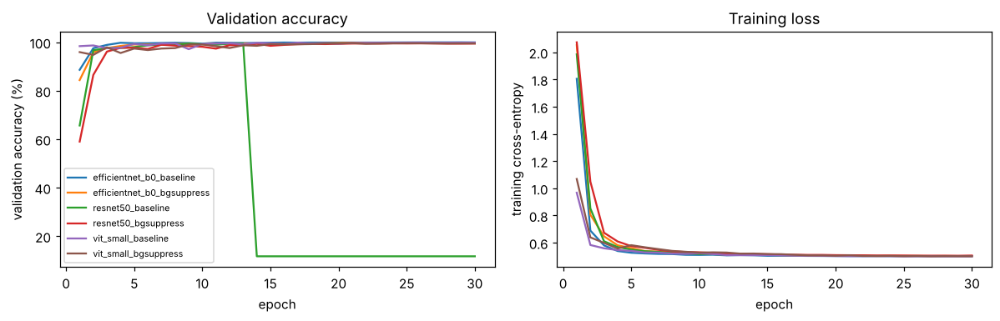

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for r in RUNS:
    log = pd.read_csv(f"runs/{r}/log.csv")
    ax[0].plot(log.epoch + 1, log.val_acc * 100, label=r)
    ax[1].plot(log.epoch + 1, log.train_ce, label=r)
ax[0].set(xlabel="epoch", ylabel="validation accuracy (%)", title="Validation accuracy")
ax[1].set(xlabel="epoch", ylabel="training cross-entropy", title="Training loss")
ax[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 5. Evaluation

Each best checkpoint was scored with `python evaluate.py --all` on: the lab test set, background-only images, Mixed-Rand background swaps, Grad-CAM focus (LFS = share of Grad-CAM energy on the leaf mask) and the PlantDoc field set. 95% confidence intervals are from 1,000 bootstrap resamples.

In [17]:
res = pd.read_csv("results/results.csv").set_index("run").loc[RUNS]
cols = ["acc", "acc_lo", "acc_hi", "macro_f1", "lfs", "lfs_random", "bgonly_acc", "mixed_acc", "shortcut_gap"]
display(res[cols].round(3))

,acc,acc_lo,acc_hi,macro_f1,lfs,lfs_random,bgonly_acc,mixed_acc,shortcut_gap
run,,,,,,,,,
efficientnet_b0_baseline,99.816,99.633,99.963,99.781,0.839,0.517,24.046,87.518,12.298
efficientnet_b0_bgsuppress,99.596,99.339,99.816,99.504,0.985,0.517,12.518,99.302,0.294
resnet50_baseline,99.229,98.862,99.523,98.990,0.905,0.517,22.210,95.962,3.267
resnet50_bgsuppress,99.192,98.825,99.523,98.940,0.994,0.517,13.546,99.119,0.073
vit_small_baseline,99.853,99.670,99.963,99.842,0.602,0.517,27.863,86.050,13.803
vit_small_bgsuppress,99.486,99.192,99.743,99.462,0.981,0.517,5.984,99.192,0.294


In [18]:
display(res[["field_n", "field_acc", "field_acc_lo", "field_acc_hi", "field_f1"]].round(2))

,field_n,field_acc,field_acc_lo,field_acc_hi,field_f1
run,,,,,
efficientnet_b0_baseline,744,25.27,22.31,28.23,16.10
efficientnet_b0_bgsuppress,744,25.81,22.72,29.17,19.41
resnet50_baseline,744,28.63,25.54,31.86,19.24
resnet50_bgsuppress,744,28.63,25.27,31.99,20.22
vit_small_baseline,744,26.48,23.39,29.70,18.68
vit_small_bgsuppress,744,28.50,25.27,31.86,20.83


In [19]:
# Baseline vs BG-Suppress: change per model
rows = []
for m in ["efficientnet_b0", "resnet50", "vit_small"]:
    b, s = res.loc[f"{m}_baseline"], res.loc[f"{m}_bgsuppress"]
    rows.append({"model": m,
                 "lab acc change": round(s.acc - b.acc, 2),
                 "LFS": f"{b.lfs:.3f} -> {s.lfs:.3f}",
                 "bg-only acc": f"{b.bgonly_acc:.1f} -> {s.bgonly_acc:.1f}",
                 "shortcut gap": f"{b.shortcut_gap:.2f} -> {s.shortcut_gap:.2f}",
                 "field acc": f"{b.field_acc:.1f} -> {s.field_acc:.1f}",
                 "field F1": f"{b.field_f1:.1f} -> {s.field_f1:.1f}"})
display(pd.DataFrame(rows))

,model,lab acc change,LFS,bg-only acc,shortcut gap,field acc,field F1
0,efficientnet_b0,-0.22,0.839 -> 0.985,24.0 -> 12.5,12.30 -> 0.29,25.3 -> 25.8,16.1 -> 19.4
1,resnet50,-0.04,0.905 -> 0.994,22.2 -> 13.5,3.27 -> 0.07,28.6 -> 28.6,19.2 -> 20.2
2,vit_small,-0.37,0.602 -> 0.981,27.9 -> 6.0,13.80 -> 0.29,26.5 -> 28.5,18.7 -> 20.8


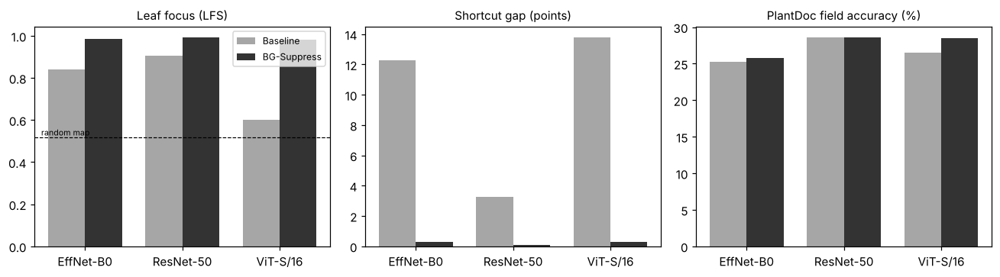

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
labels = ["EffNet-B0", "ResNet-50", "ViT-S/16"]
x = np.arange(3); w = 0.38
for k, (col, title) in enumerate([("lfs", "Leaf focus (LFS)"), ("shortcut_gap", "Shortcut gap (points)"),
                                   ("field_acc", "PlantDoc field accuracy (%)")]):
    base = [res.loc[f"{m}_baseline", col] for m in ["efficientnet_b0", "resnet50", "vit_small"]]
    supp = [res.loc[f"{m}_bgsuppress", col] for m in ["efficientnet_b0", "resnet50", "vit_small"]]
    ax[k].bar(x - w / 2, base, w, label="Baseline", color="0.65")
    ax[k].bar(x + w / 2, supp, w, label="BG-Suppress", color="0.2")
    ax[k].set_xticks(x, labels); ax[k].set_title(title, fontsize=10)
ax[0].axhline(res.lfs_random.iloc[0], ls="--", c="k", lw=0.8); ax[0].text(-0.45, res.lfs_random.iloc[0] + 0.01, "random map", fontsize=7)
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 6. Per-class results (lab test set)

In [21]:
pc = pd.read_csv("runs/efficientnet_b0_baseline/per_class.csv")
print("efficientnet_b0_baseline")
print(pc.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

efficientnet_b0_baseline
           class   lfs     acc  bgonly_acc
  Bacterial spot 0.892 100.000       6.897
    Early blight 0.796  98.000      92.000
     Late blight 0.788 100.000      62.369
       Leaf mold 0.888 100.000       4.196
        Septoria 0.812 100.000      76.692
    Spider mites 0.884 100.000       9.960
     Target spot 0.906  99.524      14.286
Yellow leaf curl 0.792  99.876       0.995
    Mosaic virus 0.909 100.000       1.786
         Healthy 0.886 100.000      17.647


In [22]:
pc = pd.read_csv("runs/efficientnet_b0_bgsuppress/per_class.csv")
print("efficientnet_b0_bgsuppress")
print(pc.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

efficientnet_b0_bgsuppress
           class   lfs     acc  bgonly_acc
  Bacterial spot 0.999 100.000       0.000
    Early blight 0.994  97.333      58.000
     Late blight 0.877  99.652      34.146
       Leaf mold 0.994  99.301       0.000
        Septoria 0.997  99.624      57.895
    Spider mites 0.997  99.602       0.398
     Target spot 0.998  99.048       0.000
Yellow leaf curl 0.999  99.876       0.000
    Mosaic virus 0.994 100.000       0.000
         Healthy 0.999 100.000       0.420


In [23]:
pc = pd.read_csv("runs/resnet50_baseline/per_class.csv")
print("resnet50_baseline")
print(pc.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

resnet50_baseline
           class   lfs     acc  bgonly_acc
  Bacterial spot 0.832 100.000      62.069
    Early blight 0.889  95.333      20.000
     Late blight 0.813  99.652      40.767
       Leaf mold 0.888  97.902       4.895
        Septoria 0.906 100.000       4.887
    Spider mites 0.944  99.203       0.398
     Target spot 0.953  98.571       0.000
Yellow leaf curl 0.953  99.378       0.124
    Mosaic virus 0.862 100.000       0.000
         Healthy 0.894 100.000     100.000


In [24]:
pc = pd.read_csv("runs/resnet50_bgsuppress/per_class.csv")
print("resnet50_bgsuppress")
print(pc.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

resnet50_bgsuppress
           class   lfs     acc  bgonly_acc
  Bacterial spot 0.997  99.373       0.940
    Early blight 0.984  96.667      53.333
     Late blight 0.975 100.000      44.948
       Leaf mold 0.992  97.902       0.000
        Septoria 0.996  98.872       0.000
    Spider mites 0.997  98.008       0.398
     Target spot 0.998  98.571       1.429
Yellow leaf curl 0.999  99.876       0.000
    Mosaic virus 0.991 100.000       0.000
         Healthy 0.998 100.000      64.286


In [25]:
pc = pd.read_csv("runs/vit_small_baseline/per_class.csv")
print("vit_small_baseline")
print(pc.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

vit_small_baseline
           class   lfs     acc  bgonly_acc
  Bacterial spot 0.491 100.000      15.987
    Early blight 0.599  99.333      53.333
     Late blight 0.503 100.000      41.812
       Leaf mold 0.540 100.000      67.133
        Septoria 0.795 100.000      94.737
    Spider mites 0.707 100.000       3.984
     Target spot 0.664  99.048      40.476
Yellow leaf curl 0.592  99.876       1.244
    Mosaic virus 0.575 100.000       1.786
         Healthy 0.569 100.000      22.689


In [26]:
pc = pd.read_csv("runs/vit_small_bgsuppress/per_class.csv")
print("vit_small_bgsuppress")
print(pc.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

vit_small_bgsuppress
           class   lfs     acc  bgonly_acc
  Bacterial spot 0.999 100.000       0.000
    Early blight 0.933  98.667      88.667
     Late blight 0.857 100.000      10.105
       Leaf mold 0.998 100.000       0.000
        Septoria 0.999  99.624       0.000
    Spider mites 0.998  98.805       0.398
     Target spot 0.999  98.571       0.000
Yellow leaf curl 1.000  99.502       0.000
    Mosaic virus 0.998 100.000       0.000
         Healthy 0.999  99.580       0.000


## 7. Field test (PlantDoc) confusion matrices

Rows are true classes, columns are predicted classes, restricted to the 8 classes present in PlantDoc.

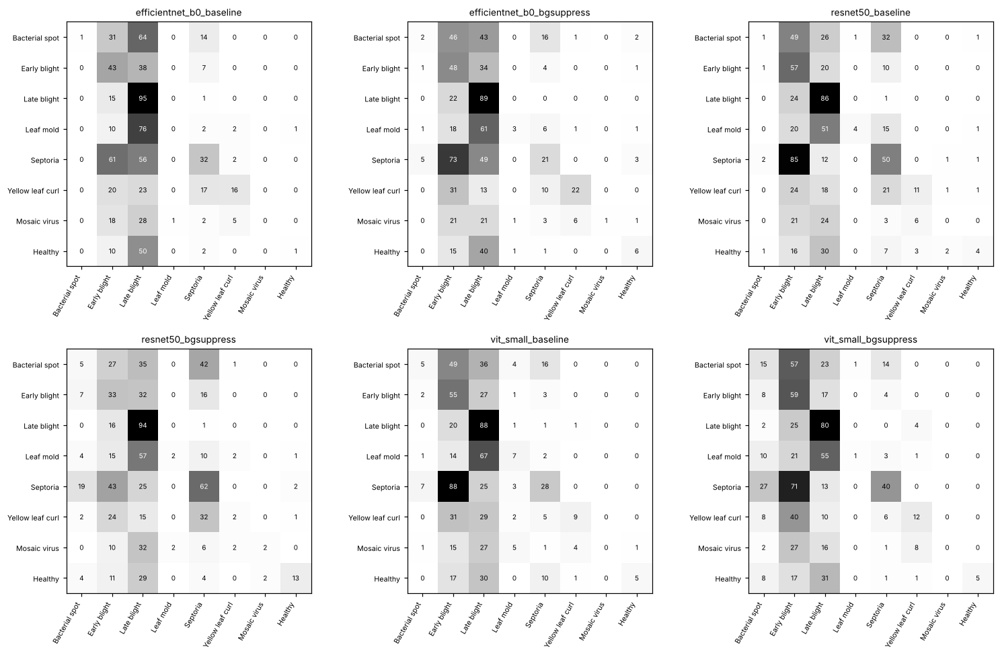

In [27]:
field_labels = [C.SHORT_NAMES[i] for i in C.FIELD_CLASSES]
fig, axes = plt.subplots(2, 3, figsize=(14, 9))
for ax, r in zip(axes.flat, RUNS):
    cm = np.load(f"runs/{r}/field_confusion.npy")
    ax.imshow(cm, cmap="Greys")
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=6.5,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks(range(len(field_labels)), field_labels, rotation=60, ha="right", fontsize=7)
    ax.set_yticks(range(len(field_labels)), field_labels, fontsize=7)
    ax.set_title(r, fontsize=9)
plt.tight_layout(); plt.show()

In [28]:
recall = {}
for r in RUNS:
    cm = np.load(f"runs/{r}/field_confusion.npy")
    recall[r] = np.round(100 * np.diag(cm) / cm.sum(1), 1)
display(pd.DataFrame(recall, index=field_labels))

,efficientnet_b0_baseline,efficientnet_b0_bgsuppress,resnet50_baseline,resnet50_bgsuppress,vit_small_baseline,vit_small_bgsuppress
Bacterial spot,0.9,1.8,0.9,4.5,4.5,13.6
Early blight,48.9,54.5,64.8,37.5,62.5,67.0
Late blight,85.6,80.2,77.5,84.7,79.3,72.1
Leaf mold,0.0,3.3,4.4,2.2,7.7,1.1
Septoria,21.2,13.9,33.1,41.1,18.5,26.5
Yellow leaf curl,21.1,28.9,14.5,2.6,11.8,15.8
Mosaic virus,0.0,1.9,0.0,3.7,0.0,0.0
Healthy,1.6,9.5,6.3,20.6,7.9,7.9


## 8. Grad-CAM comparison

Same six lab test images for every run (`results/fig_gradcam_grid.png`, produced by `make_figures.py`).

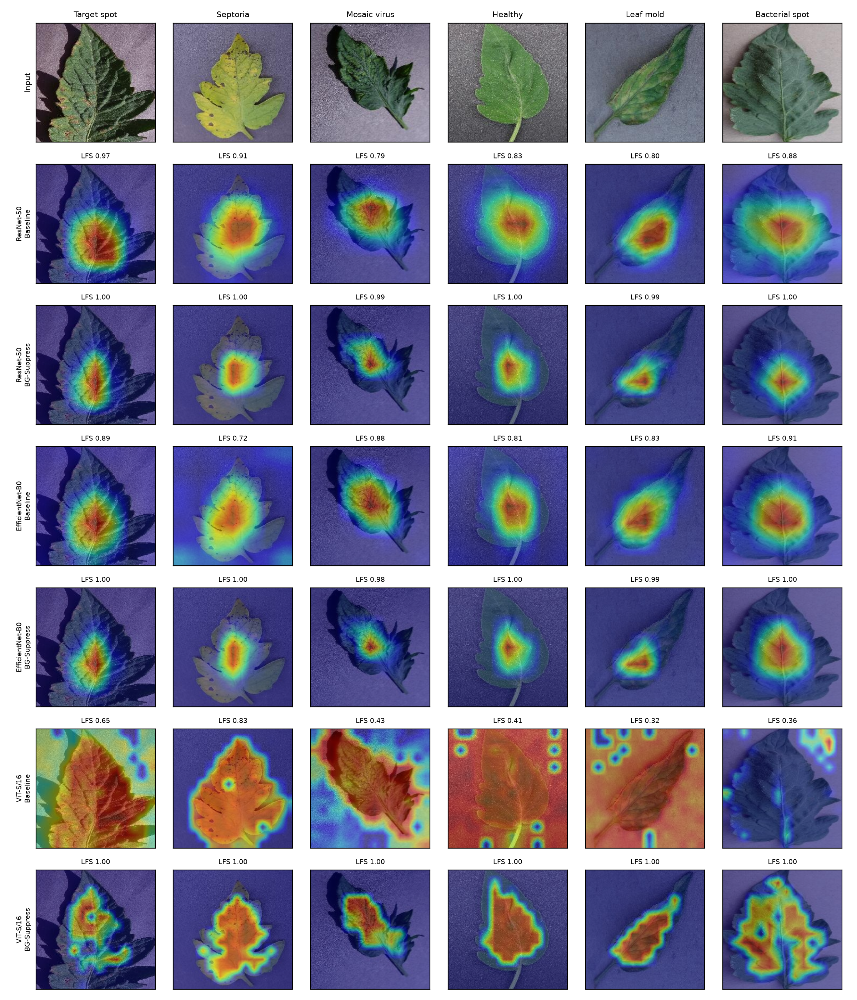

In [29]:
display(Image(filename="results/fig_gradcam_grid.png", width=900))

## 9. Summary of observations

- **Shortcut reliance.** BG-Suppress raises leaf focus (LFS) to 0.98–0.99 for all three models and cuts the Mixed-Rand shortcut gap to 0.3 points or less; background-only accuracy falls for every model.
- **Lab accuracy.** The cost of BG-Suppress on the lab test set is 0.04–0.37 percentage points.
- **ViT-S/16** is the most background-reliant baseline (LFS 0.602, close to the 0.517 of a random map; shortcut gap 13.8 points).
- **Field accuracy** stays between 25% and 29% for all runs, only modestly above the 20.3% majority-class baseline, and BG-Suppress does not change it significantly (confidence intervals overlap). Most field images are predicted as Early or Late blight.
- **Caveats.** LFS measures focus on the leaf, not on the lesion itself, and BG-Suppress optimises a related quantity during training; the background-only and Mixed-Rand tests provide the independent evidence. The ResNet-50 baseline was evaluated at its epoch-9 checkpoint because training became unstable at epoch 14.